In [1]:
#Task 1: KNN to classify Flipkart reviews as positive or negative
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

rv = pd.read_csv("flipkart_reviews.csv")
xtr, xte, ytr, yte = train_test_split(rv["review"], rv["label"], test_size=0.25, random_state=1, stratify=rv["label"])

cv = CountVectorizer(stop_words="english")
xtr_n = cv.fit_transform(xtr)
xte_n = cv.transform(xte)

knn = KNeighborsClassifier(n_neighbors=3, metric="cosine")
knn.fit(xtr_n, ytr)
print("Accuracy:", accuracy_score(yte, knn.predict(xte_n)))

new = ["very good product, loved it", "bad quality, waste of money"]
print(new)
print("Predictions for new reviews:", knn.predict(cv.transform(new)))

# KNN looks at the 3 closest training reviews and takes the majority label.
# Words like good, great, bad and waste decide which reviews are close. With a small dataset the accuracy can change if the split changes.

Accuracy: 0.8666666666666667
['very good product, loved it', 'bad quality, waste of money']
Predictions for new reviews: ['positive' 'negative']


In [2]:
#Task 2: KNN with Euclidean vs Manhattan distance on Spotify songs
from sklearn.preprocessing import StandardScaler

sp = pd.read_csv("spotify_playlists.csv")
X = sp[["tempo", "danceability", "energy"]]
y = sp["playlist"]
xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

# scale the features, otherwise tempo (big numbers) would dominate the distance
sc = StandardScaler()
xtr_s = sc.fit_transform(xtr)
xte_s = sc.transform(xte)

for m in ["euclidean", "manhattan"]:
    k = KNeighborsClassifier(n_neighbors=5, metric=m)
    k.fit(xtr_s, ytr)
    print(m, "accuracy:", round(accuracy_score(yte, k.predict(xte_s)), 3))

# Euclidean gave a slightly better accuracy (0.917) than Manhattan (0.867) here.
# The test set has only 60 songs, so the difference is just 3 songs and both metrics work well on this data.

euclidean accuracy: 0.917
manhattan accuracy: 0.867


In [3]:
#Task 3: Gaussian Naive Bayes for IRCTC booking status
from sklearn.naive_bayes import GaussianNB

ir = pd.read_csv("irctc_bookings.csv")
X = ir[["days_before_travel", "train_popularity", "travel_day"]]
y = ir["status"]
xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

gnb = GaussianNB()
gnb.fit(xtr, ytr)
print("Accuracy:", round(accuracy_score(yte, gnb.predict(xte)), 3))

# a new booking: 5 days before travel, popular train (9), travel day 4 (Friday)
nb = pd.DataFrame([[5, 9, 4]], columns=X.columns)
print("New booking prediction:", gnb.predict(nb)[0])

Accuracy: 0.833
New booking prediction: waitlisted


In [4]:
#Task 4: Multinomial Naive Bayes for WhatsApp messages with confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix

wa = pd.read_csv("whatsapp_messages.csv")
xtr, xte, ytr, yte = train_test_split(wa["message"], wa["label"], test_size=0.3, random_state=1, stratify=wa["label"])

cv2 = CountVectorizer()
xtr_n = cv2.fit_transform(xtr)
xte_n = cv2.transform(xte)

mnb = MultinomialNB()
mnb.fit(xtr_n, ytr)
pred = mnb.predict(xte_n)

print("Accuracy:", round(accuracy_score(yte, pred), 3))

labs = ["personal", "group", "spam"]
cm = confusion_matrix(yte, pred, labels=labs)
print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=labs, columns=labs))

Accuracy: 0.913
Confusion matrix (rows = actual, columns = predicted):
          personal  group  spam
personal         6      1     1
group            0      7     0
spam             0      0     8


Accuracy: 1.0


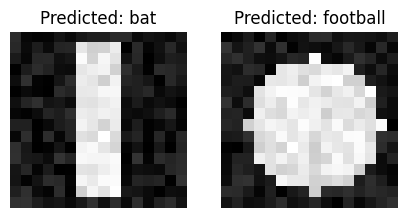

In [5]:
#Task 5: KNN image classifier for cricket bats vs footballs (random pixel arrays)
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

def make_image(kind):
    img = rng.random((16, 16)) * 0.2          # random dark noise
    if kind == "bat":
        img[1:15, 6:10] += 0.8                # tall bright strip looks like a bat
    else:
        yy, xx = np.ogrid[:16, :16]
        circle = (yy - 8) ** 2 + (xx - 8) ** 2 <= 36
        img[circle] += 0.8                    # bright round blob looks like a ball
    return img

imgs = []
labels = []
for i in range(60):
    imgs.append(make_image("bat"))
    labels.append("bat")
    imgs.append(make_image("football"))
    labels.append("football")

imgs = np.array(imgs)
X = imgs.reshape(len(imgs), -1)               # flatten each 16x16 image into 256 numbers
y = np.array(labels)

xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

ki = KNeighborsClassifier(n_neighbors=3)
ki.fit(xtr, ytr)
print("Accuracy:", accuracy_score(yte, ki.predict(xte)))

# show 2 sample images with the model prediction
plt.figure(figsize=(5, 2.5))
for j, kind in enumerate(["bat", "football"]):
    t = make_image(kind)
    plt.subplot(1, 2, j + 1)
    plt.imshow(t, cmap="gray")
    plt.title("Predicted: " + ki.predict(t.reshape(1, -1))[0])
    plt.axis("off")
plt.show()

# The images are random noise with a bright strip (bat) or a bright circle (football), so this is an easy task and the accuracy is high.
# Each 16x16 image is flattened into 256 numbers, because KNN needs one flat row of numbers for every sample.
# Real photos would need many more images and better features.